# Centrality

In the previous sections, we have looked at the structure of networks. Next, we want to find out which nodes and edges are the most important ones in a network. For instance, a street can be important because many routes go through it, and an intersection can be important because it is close to all other places in the network.

In network analysis, the importance of a node or an edge is measured with **centrality** measures. There is no single definition of what makes a node important, and hence there are many different centrality measures. In the following, we go through three commonly used measures: degree centrality, betweenness centrality and closeness centrality. You can read the Wikipedia article about different centrality measures[^centrality] if you are interested what the other centrality measures mean.

We use the same simplified street network of the Helsinki city centre as in Chapter 8.4. Let's retrieve it from OpenStreetMap, keep its largest strongly connected component (see Chapter 8.3) and simplify it (see Chapter 8.4):

In [1]:
import networkx as nx
import osmnx as ox
import pandas as pd

center_point = (60.162, 24.937)
G = ox.graph_from_point(center_point, dist=3500, network_type="drive", simplify=False)
G = ox.truncate.largest_component(G, strongly=True)
G_simplified = ox.simplify_graph(G)

## Degree centrality

**Degree centrality** is a simple centrality measure that counts how many neighbors a node has, i.e. how many other nodes it is directly connected to. To make the values comparable between networks of different sizes, the degree is divided by the number of other nodes in the network, i.e. degree centrality tells the fraction of nodes that a node is connected to.

Let's calculate the degree centrality with the `nx.degree_centrality()` function. As in Chapter 8.4, we use an undirected version of our simplified network, so that each street segment is counted only once. To compare the degree centrality with the degree, we add both to the nodes of the network, and show only one node for each value of the degree to keep the output short:

In [2]:
G_simplified_undirected = ox.convert.to_undirected(G_simplified)

nodes_simplified, edges_simplified = ox.graph_to_gdfs(G_simplified)
nodes_simplified["degree"] = pd.Series(dict(G_simplified_undirected.degree()))
nodes_simplified["degree_centrality"] = pd.Series(
    nx.degree_centrality(G_simplified_undirected)
)
degrees = nodes_simplified[["degree", "degree_centrality"]]
degrees.drop_duplicates("degree").sort_values("degree")

,degree,degree_centrality
osmid,,
25470397,1,0.000564
25198522,2,0.001129
132105,3,0.001693
25198968,4,0.002257
25344880,5,0.002822
247359926,6,0.003386


As we can see, degree centrality is directly related to the degree: a node with degree 2 has twice the degree centrality of a node with degree 1, a node with degree 3 has three times as much, and so on. Hence, within a single network, degree centrality shows the same pattern as the degree itself, and it is mainly useful when we want to compare networks of different sizes.

## Betweenness centrality

**Betweenness centrality** measures how often a node or an edge lies on the shortest paths between all pairs of nodes in the network. In a street network, the streets with high betweenness centrality are the ones that many of the shortest routes go through.

Let's calculate the betweenness centrality for each edge of our network with the `nx.edge_betweenness_centrality()` function (the `nx.betweenness_centrality()` function does the same for nodes). We use the length of the edges as the weight, so that the shortest paths are based on distance. The calculation can take a while, because the function needs to find the shortest paths between all pairs of nodes:

In [3]:
edge_betweenness = nx.edge_betweenness_centrality(G_simplified, weight="length")
edges_simplified["betweenness"] = pd.Series(edge_betweenness)

As a result, we get a dictionary in which the keys identify each edge by its `u`, `v` and `key` values (the same values that `osmnx` uses as the index of the edges, see Chapter 8.2) and the values are the betweenness centralities, which we added as a new column to the `edges_simplified` GeoDataFrame. Because our graph is directed, the shortest paths follow the allowed driving directions. Let's plot the streets on a map and color them by their betweenness centrality:

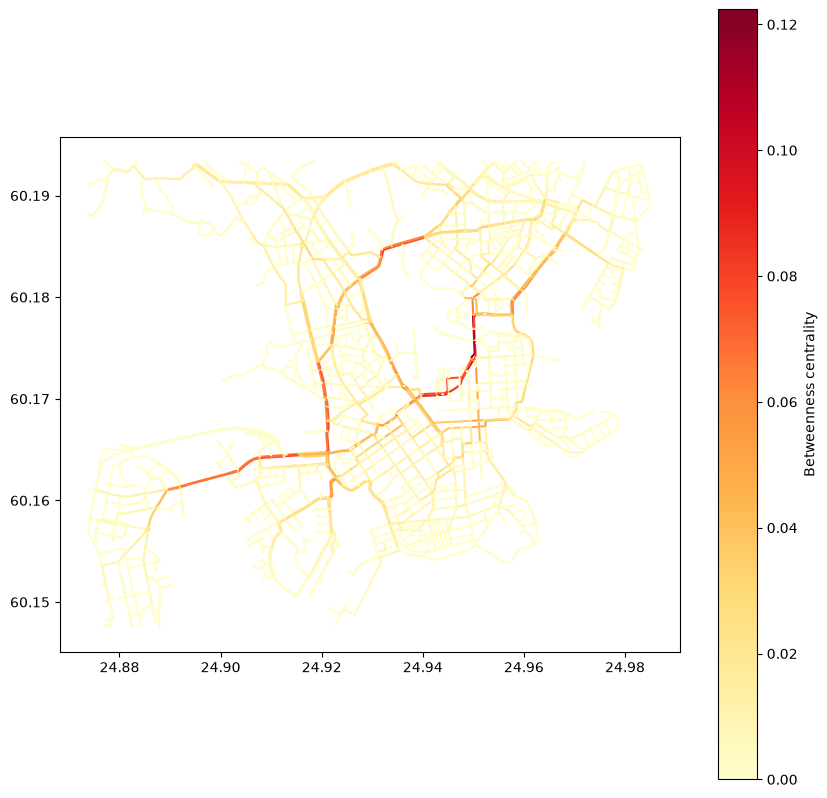

In [4]:
ax = edges_simplified.plot(
    column="betweenness",
    cmap="YlOrRd",
    linewidth=1.5,
    figsize=(10, 10),
    legend=True,
    legend_kwds={"label": "Betweenness centrality"},
)

_**Figure 8.30.** Betweenness centrality of the streets in the Helsinki city centre._

In the map, the streets with high betweenness centrality (in dark red) are the ones that many of the shortest routes between different parts of the area pass through, whereas the light yellow streets are rarely part of the shortest routes between other places. Typically, the streets with the highest values are main streets, because they connect different parts of the city.

## Closeness centrality

**Closeness centrality** measures how easily a node can be reached from all other nodes in the network. It is based on the average shortest path distance from all other nodes to the node: the shorter the average distance, the higher the closeness centrality. Let's calculate the closeness centrality for each node with the `nx.closeness_centrality()` function. Here, the `distance` parameter tells which edge attribute to use as the distance between the nodes:

In [5]:
closeness = nx.closeness_centrality(G_simplified, distance="length")
nodes_simplified["closeness"] = pd.Series(closeness)

As a result, we get a dictionary with the closeness centrality of each node, which we added as a new column to the `nodes_simplified` GeoDataFrame. The closeness centrality is one divided by the average distance, and because our distances are in meters, the values are very small numbers that are mainly useful for comparing the nodes with each other. Let's plot the nodes on a map and color them by their closeness centrality:

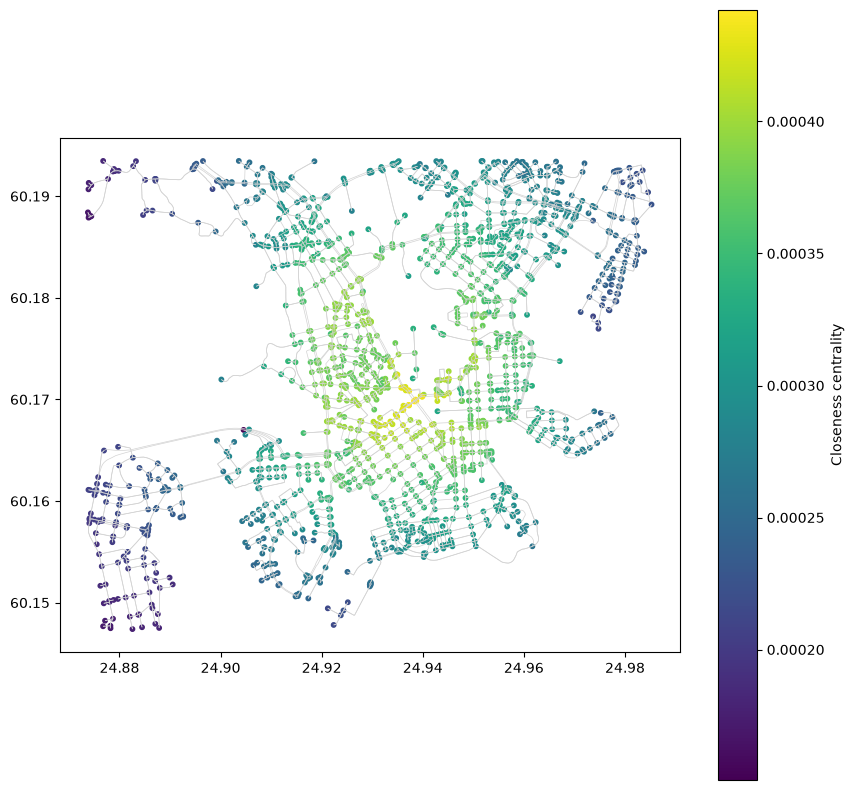

In [6]:
ax = edges_simplified.plot(color="lightgrey", linewidth=0.5, figsize=(10, 10))
ax = nodes_simplified.plot(
    ax=ax,
    column="closeness",
    cmap="viridis",
    markersize=10,
    legend=True,
    legend_kwds={"label": "Closeness centrality"},
)

_**Figure 8.31.** Closeness centrality of the nodes in the street network._

As we can see, closeness centrality is highest in the central parts of the street network and decreases towards its edges, as the nodes in the central parts are on average closer to all other nodes. However, part of this pattern is caused by the fact that our data ends at the border of the area, whereas in reality the street network continues beyond it. This is the edge effect that we discussed in Chapter 8.3, and it affects betweenness centrality as well.

In this section, we learned how to measure the importance of nodes and edges with centrality measures. Public transport routes and stops form networks as well, and they can be combined with street networks. In Chapter 11, we will use such multimodal networks that combine several modes of transport, such as walking and public transport, to calculate travel times for accessibility analysis.

## Footnotes

[^centrality]: <https://en.wikipedia.org/wiki/Centrality>